In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")



All libraries imported successfully!


In [19]:

import pandas as pd

df = pd.read_csv('retail_sales_dataset.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())


Dataset Shape: (1000, 9)

First 5 Rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [20]:

# Task 1: Mean, Median and Mode

sales = df['Total Amount']

mean_sales = sales.mean()
median_sales = sales.median()
mode_sales = sales.mode()

print("Mean:", mean_sales)
print("Median:", median_sales)
print("Mode:", mode_sales.tolist())


Mean: 456.0
Median: 135.0
Mode: [50]


**Interpretation:**

- **Mean:** Represents the average transaction amount.
- **Median:** Represents the middle transaction amount.
- **Mode:** Represents the most frequently occurring transaction amount.

These measures help us understand the central tendency of the dataset.

In [21]:

# Task 2: Variance and Standard Deviation

sales = df['Total Amount']

variance_sales = sales.var()
std_sales = sales.std()

print("Variance:", variance_sales)
print("Standard Deviation:", std_sales)


Variance: 313597.34734734736
Standard Deviation: 559.997631555123


**Interpretation:**

Variance measures how much the transaction amounts vary from the mean. Standard deviation indicates the spread of transaction amounts in the original units. A higher standard deviation means greater variation, while a lower standard deviation means the values are closer to the mean.

In [22]:

# Task 3A: Correlation Analysis

correlation = df['Age'].corr(df['Total Amount'])

print("Correlation between Age and Total Amount:", correlation)

if correlation > 0:
    print("Relationship: Positive")
elif correlation < 0:
    print("Relationship: Negative")
else:
    print("Relationship: No linear correlation")


Correlation between Age and Total Amount: -0.0605680238830457
Relationship: Negative


**Interpretation:**

**Correlation:** Age and Total Amount show a very weak negative correlation, indicating little to no linear relationship between the two variables.

**Probability:** The probability of a transaction belonging to the Clothing category is approximately 35.1%. This means around 35 out of every 100 transactions belong to the Clothing category.

In [23]:

# Task 3B: Probability Calculation

total_transactions = len(df)

clothing_transactions = (
    df['Product Category'] == 'Clothing'
).sum()

probability = clothing_transactions / total_transactions

print("Total Transactions:", total_transactions)
print("Clothing Transactions:", clothing_transactions)
print("Probability:", probability)
print("Probability Percentage:", probability * 100, "%")


Total Transactions: 1000
Clothing Transactions: 351
Probability: 0.351
Probability Percentage: 35.099999999999994 %


In [24]:

# Task 4: Outlier Detection using IQR

Q1 = df['Total Amount'].quantile(0.25)
Q3 = df['Total Amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Total Amount'] < lower_limit) |
    (df['Total Amount'] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(outliers))

display(outliers)


Q1: 60.0
Q3: 900.0
IQR: 840.0
Lower Limit: -1200.0
Upper Limit: 2160.0
Number of Outliers: 0


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount


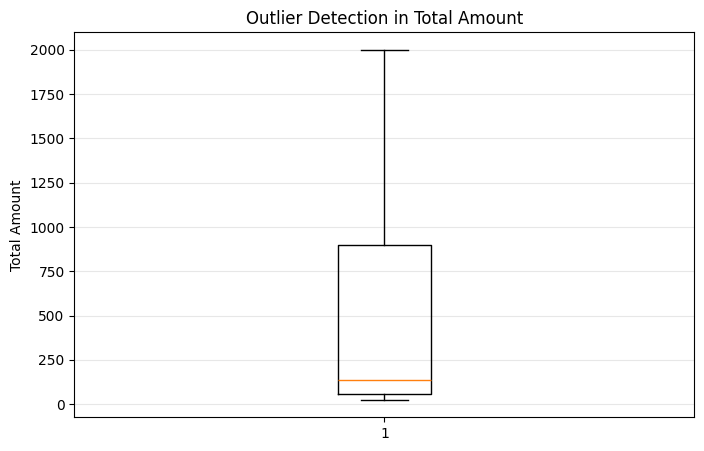

In [25]:

plt.figure(figsize=(8, 5))
plt.boxplot(df['Total Amount'])
plt.title('Outlier Detection in Total Amount')
plt.ylabel('Total Amount')
plt.grid(axis='y', alpha=0.3)
plt.show()


**Interpretation:**

The IQR (Interquartile Range) method is used to identify potential outliers. In this analysis, zero outliers were detected in the selected numerical variable. Outliers can affect the mean, standard deviation, and conclusions drawn from data, so they should be investigated carefully.

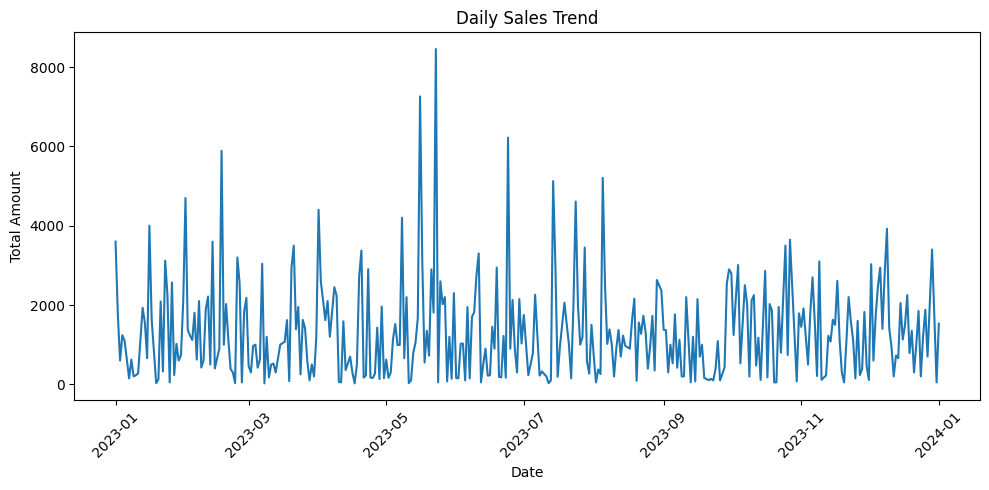

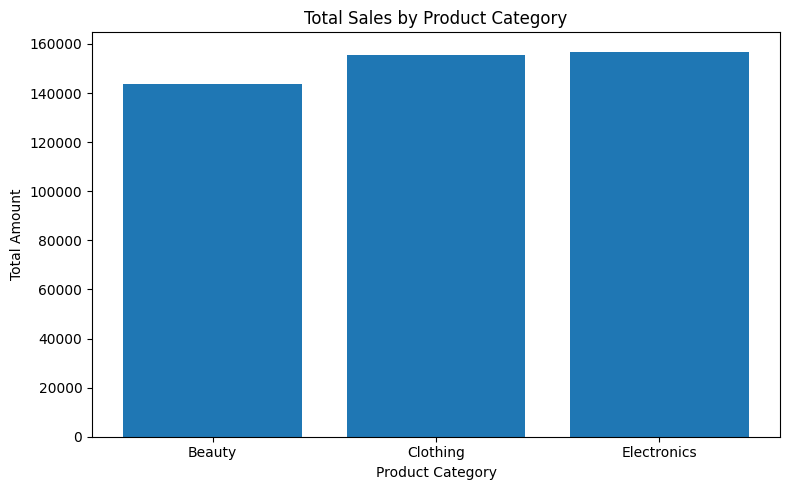

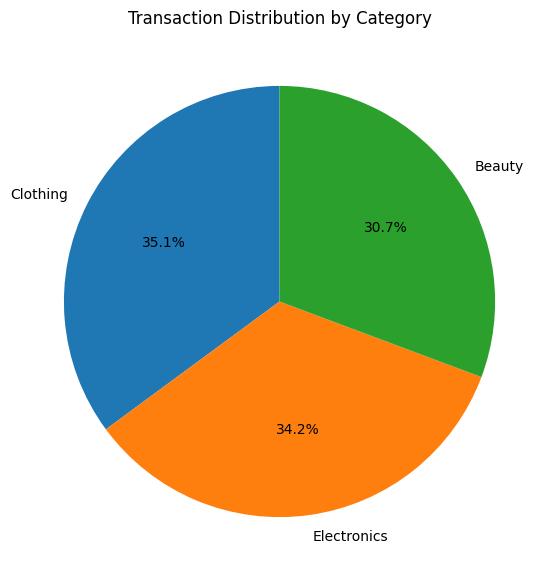

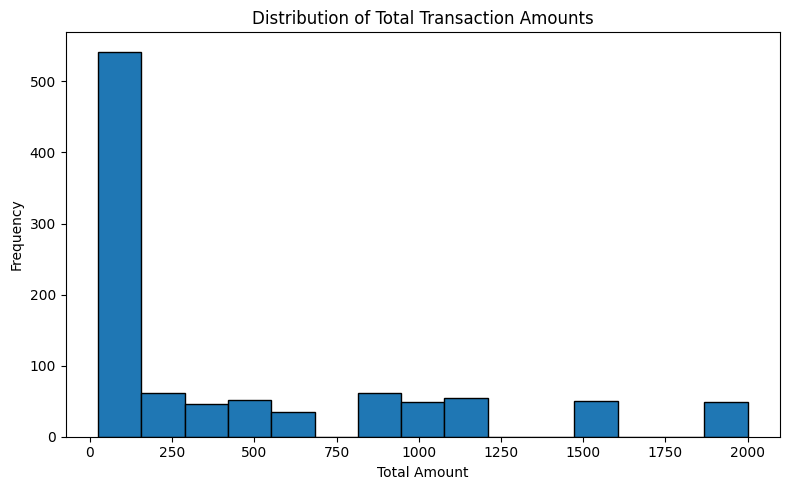

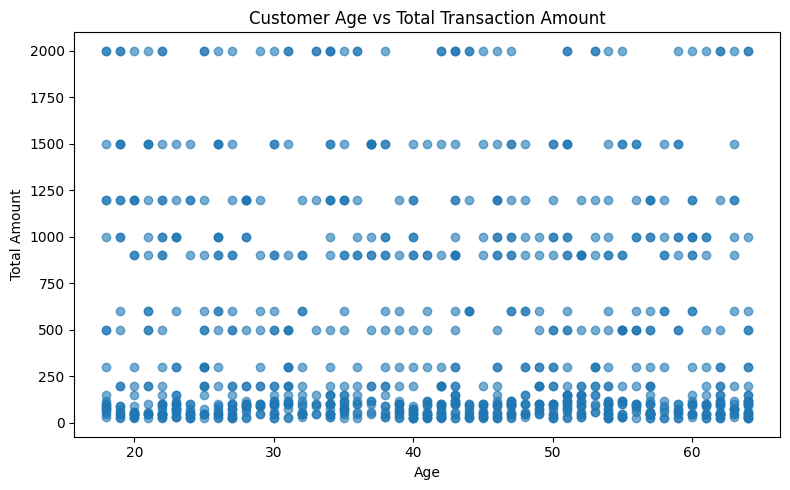

In [26]:

# Task 5: Matplotlib Visualizations

import matplotlib.pyplot as plt

# 1. Line Chart: Daily Sales Trend
df['Date'] = pd.to_datetime(df['Date'])
daily_sales = df.groupby('Date')['Total Amount'].sum().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2. Bar Chart: Sales by Product Category
category_sales = df.groupby('Product Category')['Total Amount'].sum()

plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values)
plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Amount')
plt.tight_layout()
plt.show()


# 3. Pie Chart: Transactions by Product Category
category_counts = df['Product Category'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    category_counts.values,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Transaction Distribution by Category')
plt.show()


# 4. Histogram: Distribution of Transaction Amounts
plt.figure(figsize=(8, 5))
plt.hist(df['Total Amount'], bins=15, edgecolor='black')
plt.title('Distribution of Total Transaction Amounts')
plt.xlabel('Total Amount')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


# 5. Scatter Plot: Age vs Total Amount
plt.figure(figsize=(8, 5))
plt.scatter(df['Age'], df['Total Amount'], alpha=0.6)
plt.title('Customer Age vs Total Transaction Amount')
plt.xlabel('Age')
plt.ylabel('Total Amount')
plt.tight_layout()
plt.show()


**Interpretation:**

The line chart shows how the selected values change across observations. It helps identify overall trends and variations in the data.

**Interpretation:**


The bar chart compares values across different categories. It helps identify which categories have higher values and which have lower values.


**Interpretation:**

The line chart shows how the selected values change across observations. It helps identify overall trends and variations in the data.


**Interpretation:**

The histogram shows the distribution of numerical values in the dataset. It helps us understand where most observations are concentrated and whether the data is spread out or clustered within certain ranges.


**Interpretation:**

The scatter plot shows the relationship between two numerical variables. The distribution of points helps identify whether a positive, negative, or weak relationship exists between them.

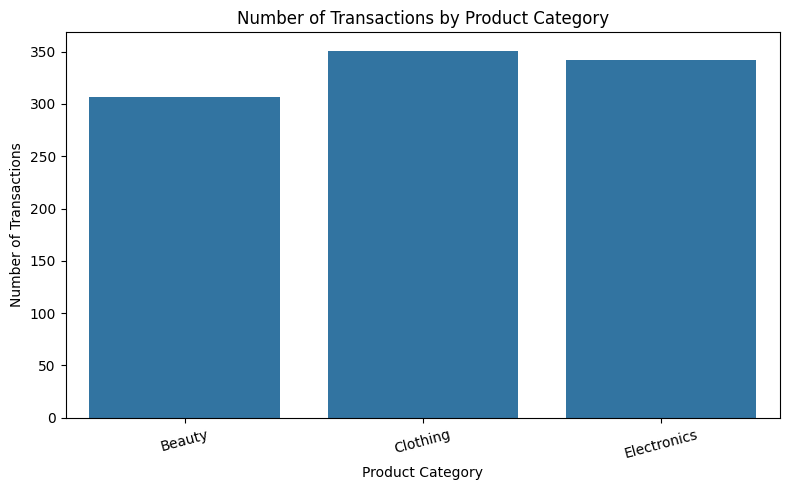

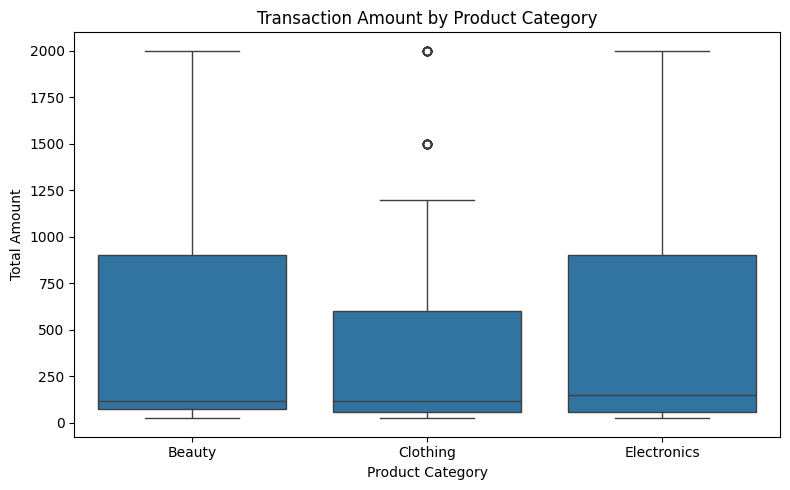

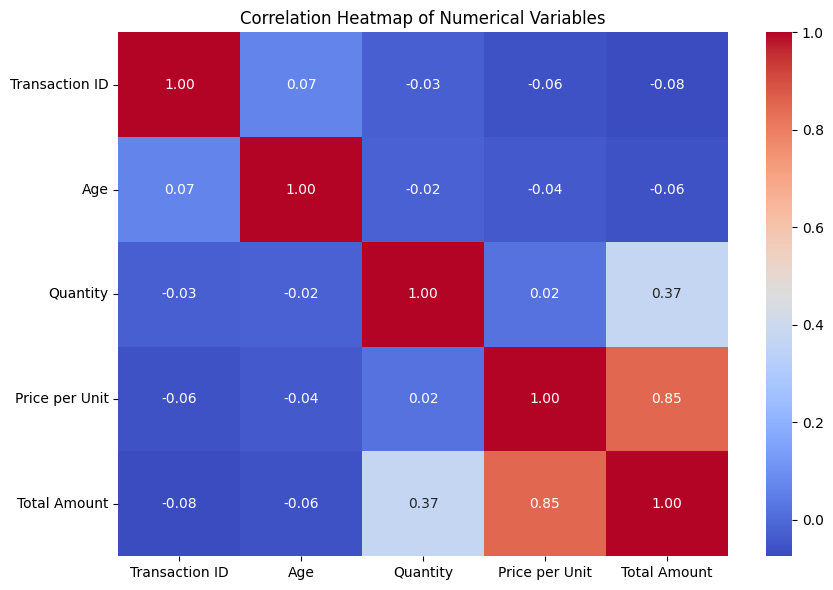

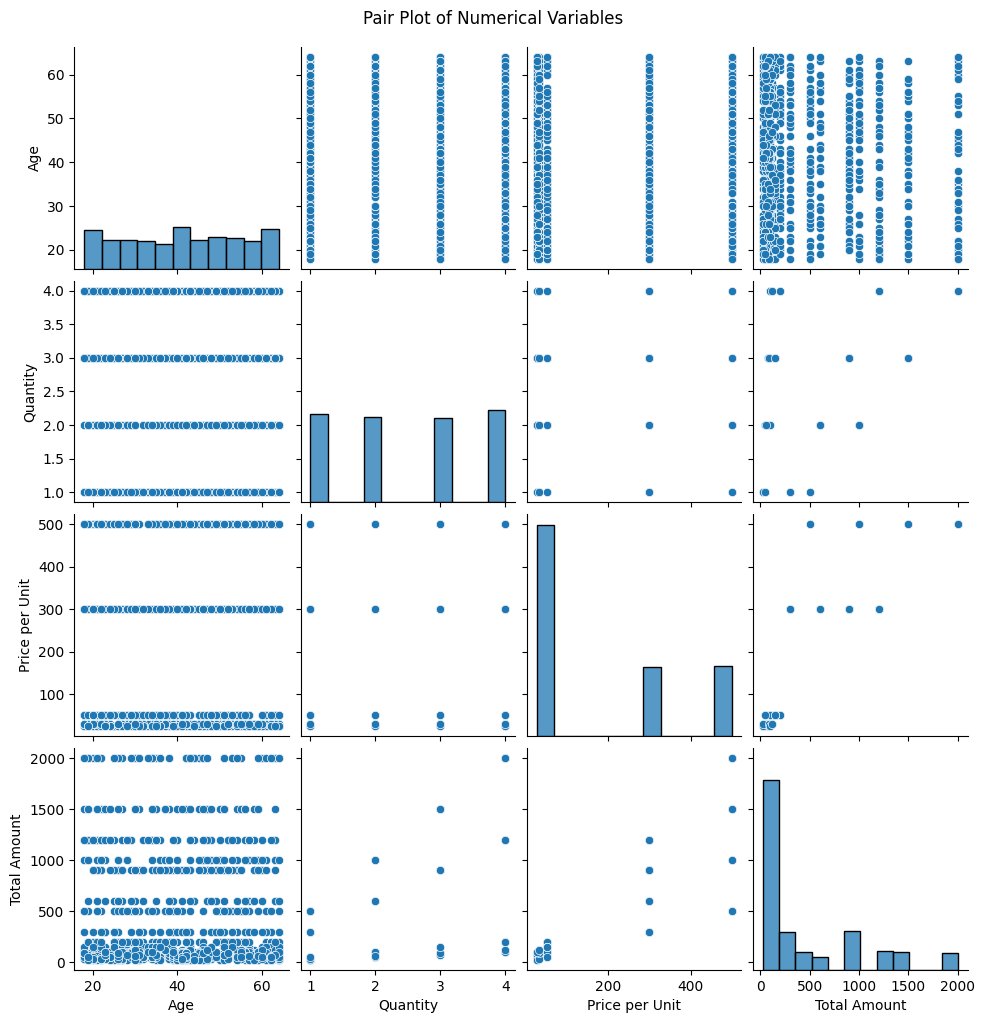

In [27]:

# Task 6: Seaborn Visualizations

import seaborn as sns
import matplotlib.pyplot as plt

# 1. Count Plot: Transactions by Product Category
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Product Category')
plt.title('Number of Transactions by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# 2. Box Plot: Transaction Amount by Product Category
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Product Category', y='Total Amount')
plt.title('Transaction Amount by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Amount')
plt.tight_layout()
plt.show()


# 3. Heatmap: Correlation Between Numerical Variables
numeric_df = df.select_dtypes(include='number')
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()


# 4. Pair Plot: Relationships Between Numerical Variables
pair_df = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']]

sns.pairplot(pair_df)
plt.suptitle('Pair Plot of Numerical Variables', y=1.02)
plt.show()


**Interpretation:**

The count plot displays the number of observations in each category. It helps identify the most and least frequent categories in the dataset.

**Interpretation:**

The box plot shows the distribution of numerical values through the median, quartiles, and spread. It also helps identify potential outliers in the data.

**Interpretation:**

The heatmap uses colours to represent the correlation between numerical variables. Positive values indicate positive relationships, negative values indicate negative relationships, and values near zero indicate weak linear relationships.

**Interpretation:**

The pair plot shows the distributions of individual numerical variables and the relationships between pairs of variables. It helps identify patterns, possible correlations, and trends in the dataset.



In [28]:

# Task 7A: Data Inspection Before Cleaning

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe(include='all'))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nExact Duplicate Rows:", df.duplicated().sum())

print("\nFirst 5 Rows Before Cleaning:")
display(df.head())


Dataset Shape: (1000, 9)

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data Types:
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

Statistical Summary:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000,1000,1000.00000,1000,1000.000000,1000.000000,1000.000000
unique,NaN,NaN,1000,2,NaN,3,NaN,NaN,NaN
top,NaN,NaN,CUST1000,Female,NaN,Clothing,NaN,NaN,NaN
freq,NaN,NaN,1,510,NaN,351,NaN,NaN,NaN
mean,500.500000,2023-07-03 00:25:55.200000256,NaN,NaN,41.39200,NaN,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,NaN,NaN,18.00000,NaN,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,NaN,NaN,29.00000,NaN,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,NaN,NaN,42.00000,NaN,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,NaN,NaN,53.00000,NaN,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,NaN,NaN,64.00000,NaN,4.000000,500.000000,2000.000000



Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Exact Duplicate Rows: 0

First 5 Rows Before Cleaning:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [29]:

# Task 7B: Data Cleaning

df_clean = df.copy()

# Handle missing numerical values using the median
numeric_cols = df_clean.select_dtypes(include='number').columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Handle missing categorical values using the mode
categorical_cols = df_clean.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates().copy()

# Convert Date column to datetime, if present
if 'Date' in df_clean.columns:
    df_clean['Date'] = pd.to_datetime(
        df_clean['Date'], errors='coerce'
    )

print("Cleaning completed!")
print("Shape after cleaning:", df_clean.shape)
print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows After Cleaning:", df_clean.duplicated().sum())

print("\nFirst 5 Rows After Cleaning:")
display(df_clean.head())


Cleaning completed!
Shape after cleaning: (1000, 9)

Missing Values After Cleaning:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows After Cleaning: 0

First 5 Rows After Cleaning:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [30]:

# Check for potentially incorrect or inconsistent values

print("Invalid Age Records:",
      ((df_clean['Age'] < 0) | (df_clean['Age'] > 120)).sum())

print("Non-positive Quantity Records:",
      (df_clean['Quantity'] <= 0).sum())

print("Non-positive Price Records:",
      (df_clean['Price per Unit'] <= 0).sum())

print("Negative Total Amount Records:",
      (df_clean['Total Amount'] < 0).sum())

print("Invalid Dates:",
      df_clean['Date'].isna().sum())


Invalid Age Records: 0
Non-positive Quantity Records: 0
Non-positive Price Records: 0
Negative Total Amount Records: 0
Invalid Dates: 0


Correlation Matrix:


,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


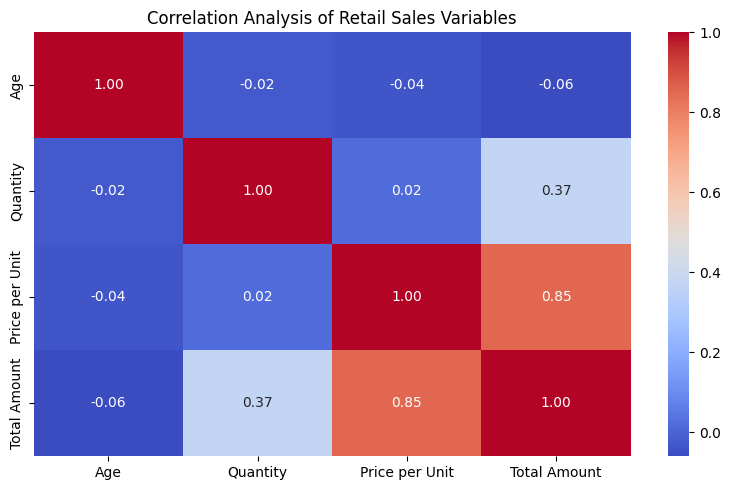

In [31]:

# Task 8: Correlation Analysis

selected_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
correlation_matrix = df_clean[selected_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(8, 5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Analysis of Retail Sales Variables')
plt.tight_layout()
plt.show()


### Additional Data Insights

1. **Category Performance:** Comparing total revenue across product categories helps identify which categories contribute the most to overall sales.

2. **Average Transaction Value:** Comparing average transaction amounts across categories helps identify categories where customers spend more per transaction.

3. **Age and Spending Relationship:** The correlation between Age and Total Amount is very weak and negative, suggesting that age alone may not be a useful linear predictor of transaction amount.

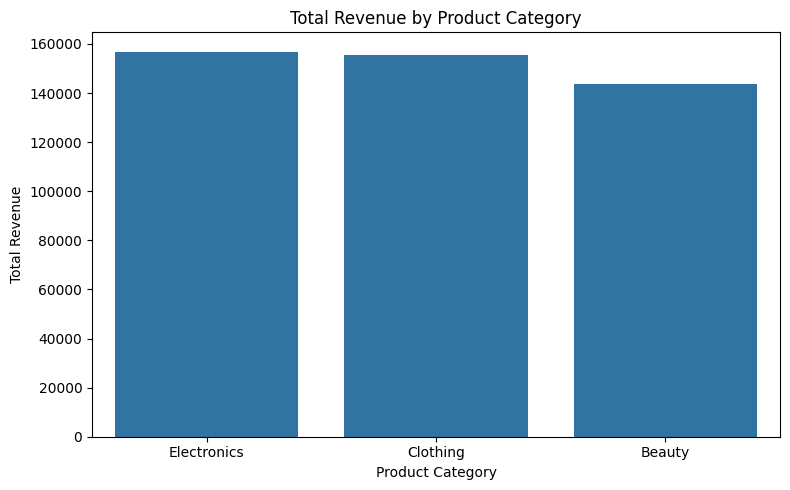

Revenue by Category:


,Total Amount
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


Highest Revenue Category: Electronics
Lowest Revenue Category: Beauty


In [32]:

# Compare sales across product categories

category_sales = (
    df_clean.groupby('Product Category')['Total Amount']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=category_sales.index, y=category_sales.values)
plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()

print("Revenue by Category:")
display(category_sales)

print("Highest Revenue Category:", category_sales.idxmax())
print("Lowest Revenue Category:", category_sales.idxmin())


In [33]:

# Generate data-driven insights

print("INSIGHT 1: Category Performance")
print(
    f"{category_sales.idxmax()} generated the highest total revenue "
    f"({category_sales.max():.2f})."
)

print("\nINSIGHT 2: Correlation")
age_corr = correlation_matrix.loc['Age', 'Total Amount']
quantity_corr = correlation_matrix.loc['Quantity', 'Total Amount']

print(
    f"Age and Total Amount correlation: {age_corr:.3f}. "
    "This indicates the direction and strength of their linear relationship."
)

print(
    f"Quantity and Total Amount correlation: {quantity_corr:.3f}. "
    "This indicates how transaction quantity relates to total amount."
)

print("\nINSIGHT 3: Average Transaction Amount")
category_avg = df_clean.groupby(
    'Product Category'
)['Total Amount'].mean().sort_values(ascending=False)

print(
    f"{category_avg.idxmax()} has the highest average transaction amount "
    f"({category_avg.max():.2f})."
)


INSIGHT 1: Category Performance
Electronics generated the highest total revenue (156905.00).

INSIGHT 2: Correlation
Age and Total Amount correlation: -0.061. This indicates the direction and strength of their linear relationship.
Quantity and Total Amount correlation: 0.374. This indicates how transaction quantity relates to total amount.

INSIGHT 3: Average Transaction Amount
Beauty has the highest average transaction amount (467.48).


In [34]:

# Task 9: Business Recommendations

category_analysis = df_clean.groupby('Product Category').agg(
    Total_Revenue=('Total Amount', 'sum'),
    Average_Transaction=('Total Amount', 'mean'),
    Total_Quantity=('Quantity', 'sum'),
    Number_of_Transactions=('Total Amount', 'count')
).sort_values('Total_Revenue', ascending=False)

print("Business Performance by Category:")
display(category_analysis)

top_revenue_category = category_analysis['Total_Revenue'].idxmax()
lowest_revenue_category = category_analysis['Total_Revenue'].idxmin()

top_avg_category = category_analysis['Average_Transaction'].idxmax()

print("\nBusiness Recommendations:")

print(
    f"1. Focus on promoting {top_revenue_category}, "
    "which generates the highest total revenue."
)

print(
    f"2. Study the pricing, product mix and customer preferences "
    f"of {top_avg_category}, which has the highest average transaction amount."
)

print(
    f"3. Review the sales performance of {lowest_revenue_category} "
    "to identify opportunities for better marketing and product placement."
)


Business Performance by Category:


,Total_Revenue,Average_Transaction,Total_Quantity,Number_of_Transactions
Product Category,,,,
Electronics,156905,458.786550,849,342
Clothing,155580,443.247863,894,351
Beauty,143515,467.475570,771,307



Business Recommendations:
1. Focus on promoting Electronics, which generates the highest total revenue.
2. Study the pricing, product mix and customer preferences of Beauty, which has the highest average transaction amount.
3. Review the sales performance of Beauty to identify opportunities for better marketing and product placement.


### Task 9: Business Recommendations

Based on the exploratory data analysis, the following business recommendations are proposed:

**1. Focus on High-Revenue Categories**

The business should continue promoting the product category that generates the highest total revenue. Targeted marketing, suitable product availability, and promotional campaigns may help maintain its sales performance.

**2. Improve Average Transaction Value**

The business should study the category with the highest average transaction amount to understand its pricing and purchasing patterns. Relevant product bundles and complementary product suggestions could help increase transaction value.

**3. Improve Low-Revenue Category Performance**

The business should investigate the category with the lowest total revenue. Reviewing customer preferences, product availability, pricing, and promotional strategies may help identify opportunities for improvement.

These recommendations are based on category-level revenue, average transaction amounts, quantities sold, and transaction counts. Their effectiveness should be evaluated using future sales data.